# 02 Slutlig demonstration och testutvärdering

Denna notebook genomför projektets slutliga utvärdering på den tidigare orörda testdatan samt demonstrerar hur huvudmodellen fattar beslut och förklaras med SHAP.

## 1. Modellval och förberedelser
### Valideringsresultat
Innan utvärdering på testdata genomfördes låstes projektets slutmodell baserat på valideringsresultaten (tidsbaserad split 2016-07-01):

| Modell | Precision@20% | Recall@20% | F1-score | PR-AUC | Korrekt flaggade (av 2329) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Baseline (lead_time)** | 54.36% | 30.83% | 39.34% | 0.5057 | 1 266 |
| **Logistic Regression (utan deposit_type)** | 60.20% | 34.14% | 43.57% | 0.5772 | 1 402 |
| **Random Forest (utan deposit_type)** | **64.75%** | **36.72%** | **46.86%** | **0.5913** | **1 508** |

### Val av slutmodell
- **Modell:** Random Forest Classifier (`n_estimators=100`, `max_depth=15`, `min_samples_leaf=10`, `random_state=42`).
- **Feature-set:** Exkluderar `deposit_type` (målvariabelläckage) och `distribution_channel` (multikollinearitet).
- **Träning för test:** Modellen tränas om på `train_full` (alla ankomster före 2016-10-01) och utvärderas en enda gång på `test` (bokningar gjorda oktober–december 2016).

### Förberedelser

In [14]:
import os

# Sätt arbetskatalog till projektroten om notebooken körs från notebooks/
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

print("Arbetskatalog:", os.getcwd())


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from src.data_split import load_cleaned_data, get_splits
from src.preprocessing import split_features_target, build_preprocessor
from src.logistic_regression import train_logistic_regression
from src.random_forest import train_random_forest
from src.prediction import predict_probabilities
from src.evaluation import evaluate_top_share, plot_pr_curve, plot_confusion_matrix, evaluate_model
from src.evaluation import flag_top_share
import matplotlib.pyplot as plt

Arbetskatalog: c:\Inlämningar\data-science-group-project


### Datainläsning och tidsuppdelning

In [2]:
df = load_cleaned_data()
splits = get_splits(df)

train_full = splits["train_full"]
test = splits["test"]

print(f"Träningsdata (train_full): {train_full.shape} (avbokningsandel: {train_full['is_canceled'].mean():.2%})")
print(f"Testdata (test):           {test.shape} (avbokningsandel: {test['is_canceled'].mean():.2%})")

2026-10-22 19:48:44 [INFO] src.data_split: Läser in städad data från data\processed\hotel_bookings_cleaned.csv
2026-10-22 19:48:45 [INFO] src.data_cleaning: Validerar städad data med Pandera...
2026-10-22 19:48:45 [INFO] src.data_cleaning: Datavalidering godkänd utan anmärkningar.
2026-10-22 19:48:45 [INFO] src.data_split: Split vid 2016-07-01: 40414 träning (avbokade 0.308), 11643 utvärdering (avbokade 0.353)
2026-10-22 19:48:45 [INFO] src.data_split: Split vid 2016-10-01: 55393 träning (avbokade 0.321), 14879 utvärdering (avbokade 0.396)
Träningsdata (train_full): (55393, 34) (avbokningsandel: 32.13%)
Testdata (test):           (14879, 34) (avbokningsandel: 39.60%)


## 2. Preprocessing och förberedelse av testdata

Preprocessorn anpassas (`fit_transform`) uteslutande på träningsmängden (`train_full`, 55 393 rader) för att förhindra dataläckage, och appliceras sedan (`transform`) på testmängden (`test`, 14 879 rader). Totalt expanderas datamängden till 127 kolumner efter One-Hot Encoding och frekvensfiltrering av agenter.

In [3]:
# Separera features och målvariabel för huvudmodellen (utan deposit_type)
X_train_full, y_train_full = split_features_target(train_full, include_deposit_type=False)
X_test, y_test = split_features_target(test, include_deposit_type=False)

# Bygg och anpassa preprocessorn endast på träningsdata
preprocessor = build_preprocessor(include_deposit_type=False)
X_train_processed = preprocessor.fit_transform(X_train_full)
X_test_processed = preprocessor.transform(X_test)

print("Transformerad träning:", X_train_processed.shape)
print("Transformerad test:   ", X_test_processed.shape)

Transformerad träning: (55393, 127)
Transformerad test:    (14879, 127)


## 3. Modellträning och riskprediktion

Vi tränar om projektets tre jämförda modeller på hela den historiska träningsdatan och genererar predicerade avbokningssannolikheter för testbokningarna.

In [4]:
# 1. Baseline: riskpoäng är lead_time direkt på test
scores_baseline = test["lead_time"]

# 2. Logistic Regression
lr_model = train_logistic_regression(X_train_processed, y_train_full)
probas_lr = predict_probabilities(lr_model, X_test_processed)

# 3. Random Forest (låsta hyperparametrar för huvudmodellen)
rf_model = train_random_forest(
    X_train_processed,
    y_train_full,
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)
probas_rf = predict_probabilities(rf_model, X_test_processed)

print("Modeller tränade och förutsägelser klara på testdata!")

Modeller tränade och förutsägelser klara på testdata!


## 4. Utvärdering på testdata vid Top 20 % flaggning

Hotellverksamheten har kapacitet att hantera proaktiva åtgärder för de 20 % mest riskfyllda bokningarna (2 976 av totalt 14 879 bokningar). 

Här utvärderas hur väl modellerna rangordnar testdatan och hur många faktiska avbokningar som fångas upp vid denna operativa gräns.

,Modell,Precision@20%,Recall@20%,F1-score,PR-AUC,Korrekt flaggade
0,Baseline (lead_time),50.81%,25.66%,34.10%,0.5043,1512
1,Logistic Regression,80.68%,40.75%,54.15%,0.7547,2401
2,Random Forest,81.75%,41.29%,54.87%,0.7750,2433


{'Baseline (lead_time)': {'pr_auc': 0.5043149998555818},
 'Logistic Regression': {'pr_auc': 0.7546623372049888},
 'Random Forest': {'pr_auc': 0.7749591683651559}}

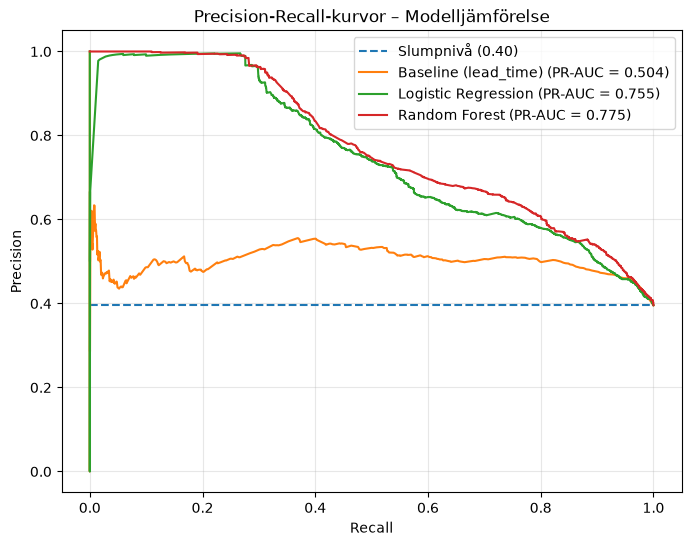

In [5]:
# Utvärdera alla modeller vid 20 % flaggning på testdata
metrics_baseline = evaluate_top_share(y_test, scores_baseline, share=0.20)
metrics_lr = evaluate_top_share(y_test, probas_lr, share=0.20)
metrics_rf = evaluate_top_share(y_test, probas_rf, share=0.20)

results_summary = pd.DataFrame([
    {
        "Modell": "Baseline (lead_time)",
        "Precision@20%": f"{metrics_baseline['precision']:.2%}",
        "Recall@20%": f"{metrics_baseline['recall']:.2%}",
        "F1-score": f"{metrics_baseline['f1_score']:.2%}",
        "PR-AUC": f"{metrics_baseline['pr_auc']:.4f}",
        "Korrekt flaggade": metrics_baseline['korrekt_flaggade']
    },
    {
        "Modell": "Logistic Regression",
        "Precision@20%": f"{metrics_lr['precision']:.2%}",
        "Recall@20%": f"{metrics_lr['recall']:.2%}",
        "F1-score": f"{metrics_lr['f1_score']:.2%}",
        "PR-AUC": f"{metrics_lr['pr_auc']:.4f}",
        "Korrekt flaggade": metrics_lr['korrekt_flaggade']
    },
    {
        "Modell": "Random Forest",
        "Precision@20%": f"{metrics_rf['precision']:.2%}",
        "Recall@20%": f"{metrics_rf['recall']:.2%}",
        "F1-score": f"{metrics_rf['f1_score']:.2%}",
        "PR-AUC": f"{metrics_rf['pr_auc']:.4f}",
        "Korrekt flaggade": metrics_rf['korrekt_flaggade']
    }
])

display(results_summary)

# Gemensam PR-kurva på testdatan
test_predictions = {
    "Baseline (lead_time)": scores_baseline,
    "Logistic Regression": probas_lr,
    "Random Forest": probas_rf
}

plot_pr_curve(y_test, test_predictions)

### Resultatanalys på testdata
* **Random Forest** är projektets starkaste modell med **81,75 % precision** och **41,29 % recall** vid 20 % flaggning (2 433 korrekt flaggade avbokningar av 2 976).
* **Jämförelse med baseline:** Baseline (`lead_time`) når endast 50,81 % precision och fångar 1 512 avbokningar. Random Forest identifierar alltså **921 fler avbokningar** vid samma arbetsinsats.
* **PR-AUC:** Random Forest uppnår **0,7750** (jämfört med 0,7547 för Logistic Regression och 0,5043 för baseline), vilket visar på en stabil rangordning över hela sannolikhetsspannet.

## 5. Modelljämförelse – City Hotel vs. Resort Hotel

### Syfte

Undersöka om Baseline, Logistic Regression och Random Forest presterar olika för City Hotel och Resort Hotel när de identifierar bokningar med hög risk för avbokning.

### Metod

Jämförelsen görs på projektets testdata med de redan tränade modellerna, utan ny träning. De 20 % mest riskfyllda bokningarna flaggas för varje modell, oavsett hotelltyp. Därefter jämförs precision och recall separat för respektive hotelltyp.

### Förberedelse av jämförelsen

Samlar hotelltyp, verkliga avbokningar och modellernas riskpoäng i en gemensam DataFrame.

In [6]:
# Samla testdata och modellernas riskpoäng
hotel_comparison = pd.DataFrame({
    "hotel": test["hotel"],
    "is_canceled": y_test,
    "baseline_score": scores_baseline,
    "lr_score": probas_lr,
    "rf_score": probas_rf,
})

hotel_comparison.head()

,hotel,is_canceled,baseline_score,lr_score,rf_score
7067,Resort Hotel,0,2,0.055435,0.102969
7127,Resort Hotel,1,1,0.046946,0.109107
7129,Resort Hotel,1,5,0.047827,0.110463
7130,Resort Hotel,1,6,0.214870,0.136827
7146,Resort Hotel,1,2,0.101167,0.122482


### Identifiera riskfyllda bokningar

För varje modell flaggar vi de 20 % bokningar som har högst riskpoäng, oavsett hotelltyp.

In [9]:
# Flagga de 20 % med högst risk för varje modell
hotel_comparison["baseline_flag"] = flag_top_share(
    hotel_comparison["baseline_score"], share=0.20
)

hotel_comparison["lr_flag"] = flag_top_share(
    hotel_comparison["lr_score"], share=0.20
)

hotel_comparison["rf_flag"] = flag_top_share(
    hotel_comparison["rf_score"], share=0.20
)

# Kontrollera antalet flaggade bokningar
hotel_comparison[
    ["baseline_flag", "lr_flag", "rf_flag"]
].sum()

baseline_flag    2976
lr_flag          2976
rf_flag          2976
dtype: int64

### Utvärdering per hotelltyp

Beräknar precision, recall och andelen flaggade bokningar för varje modell, uppdelat på City Hotel och Resort Hotel.

In [15]:
results = []

for model, flag_col in {
    "Baseline": "baseline_flag",
    "Logistic Regression": "lr_flag",
    "Random Forest": "rf_flag"
}.items():

    for hotel, group in hotel_comparison.groupby("hotel"):

        metrics = evaluate_model(
            group["is_canceled"],
            group[flag_col]
        )

        results.append({
            "Model": model,
            "Hotel": hotel,
            "Precision (%)": round(metrics["Precision"] * 100, 2),
            "Recall (%)": round(metrics["Recall"] * 100, 2),
            "Flagged (%)": round(group[flag_col].mean() * 100, 2)
        })

hotel_results = pd.DataFrame(results)

hotel_results

,Model,Hotel,Precision (%),Recall (%),Flagged (%)
0,Baseline,City Hotel,55.75,24.05,19.97
1,Baseline,Resort Hotel,40.11,32.14,20.06
2,Logistic Regression,City Hotel,82.34,46.24,26.00
3,Logistic Regression,Resort Hotel,67.18,18.67,6.96
4,Random Forest,City Hotel,85.22,44.23,24.03
5,Random Forest,Resort Hotel,65.65,29.50,11.25


### Visualisering av modellernas resultat

Stapeldiagrammen visar precision och recall för respektive modell och hotelltyp för att underlätta jämförelsen.

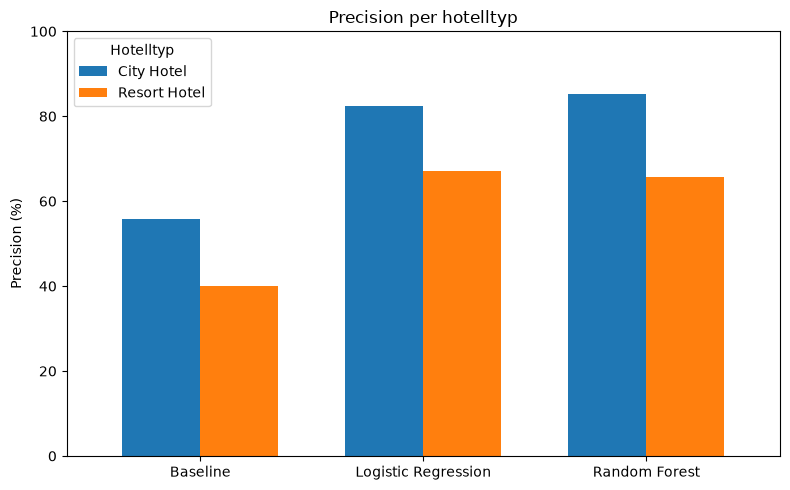

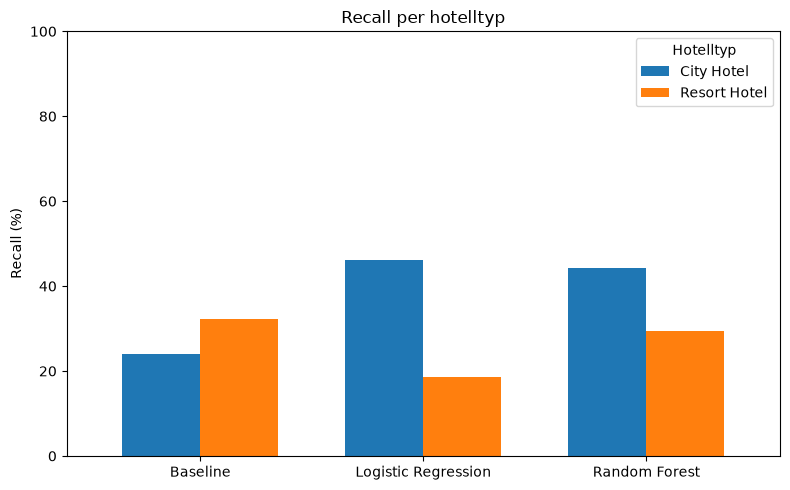

In [18]:
metrics = ["Precision (%)", "Recall (%)"]
titles = ["Precision per hotelltyp", "Recall per hotelltyp"]

for metric, title in zip(metrics, titles):

    ax = hotel_results.pivot(
        index="Model",
        columns="Hotel",
        values=metric
    ).plot(
        kind="bar",
        figsize=(8, 5),
        width=0.7
    )

    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Hotelltyp")

    plt.tight_layout()
    plt.show()

### Analys – City Hotel vs. Resort Hotel

Logistic Regression och Random Forest visar högre precision och recall för City Hotel än för Resort Hotel. Det innebär att modellerna både träffar rätt oftare och identifierar en större andel av avbokningarna på City Hotel.

Modellerna flaggar också en betydligt större andel bokningar från City Hotel, vilket kan påverka resultaten. Det kan bero på att bokningarna på City Hotel har högre avbokningsrisk, men också på att modellerna har lättare att identifiera riskerna där.

**Sammanfattningsvis visar resultaten att modellerna presterar olika för de två hotelltyperna.** En modell som fungerar bra totalt sett behöver alltså inte ge lika bra resultat för alla hotell.

## 6. Förväxlingsmatris för Random Forest

Förväxlingsmatrisen illustrerar det praktiska utfallet för hotellpersonalen:
* **True Positives (2 433 st):** Faktiska avbokningar som modellen korrekt identifierat för proaktiva åtgärder.
* **False Positives (543 st):** Bokningar som flaggats i onödan (falsklarm, under 1 av 5).
* **Ej flaggade (11 903 st):** Bokningar som lämnas utan åtgärd enligt 20 %-regeln.

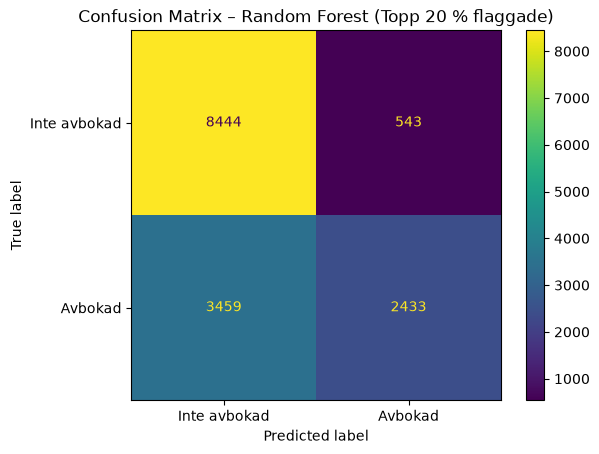

In [7]:
# 1. Identifiera och flagga de 20 % bokningarna med högst predicerad risk
y_pred_rf = pd.Series(flag_top_share(probas_rf, share=0.20), index=test.index)
y_true = pd.Series(y_test, index=test.index)

# 2. Förväxlingsmatris för Random Forest vid 20 % flaggning
fig = plot_confusion_matrix(y_true, y_pred_rf)
plt.title("Confusion Matrix – Random Forest (Topp 20 % flaggade)")
plt.show()

## 7. Förklaring av modellens bedömningar med SHAP

För att skapa transparens och förståelse för verksamheten visualiseras modellens beslutsfattande med SHAP (TreeExplainer). 

**Så läses vattenfallsdiagrammen (nedifrån och upp):**
* **Baslinjen $E[f(X)] = 0,321$:** Den genomsnittliga avbokningsrisken i träningsdatan (32,1 %).
* **Röda pilar ($+$):** Egenskaper som driver upp risken för avbokning.
* **Blå pilar ($-$)** Egenskaper som sänker risken för avbokning.
* **Slutvärdet $f(x)$:** Modellens slutgiltiga beräknade sannolikhet för den specifika bokningen.

Vi analyserar fyra representativa fall: extremt hög risk, bokningar precis över och under tröskelvärdet, samt extremt låg risk.

1. Extremt hög risk (Topp 1): Sannolikhet = 90.01%, Faktiskt utfall = Avbokad
2. Flaggad (Precis över tröskeln): Sannolikhet = 43.29%, Faktiskt utfall = Inte avbokad
3. Inte flaggad (Precis under tröskeln): Sannolikhet = 43.29%, Faktiskt utfall = Inte avbokad
4. Extremt låg risk (Botten 1): Sannolikhet = 3.52%, Faktiskt utfall = Inte avbokad


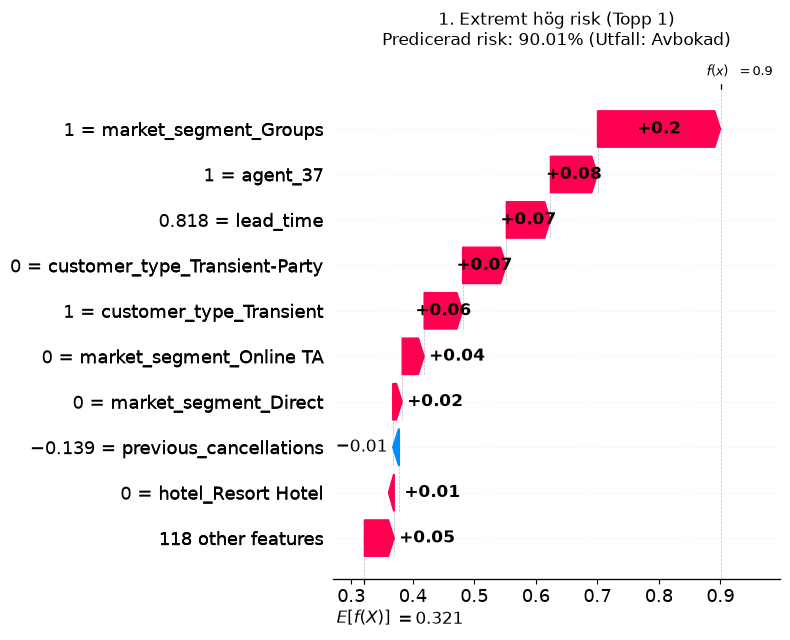

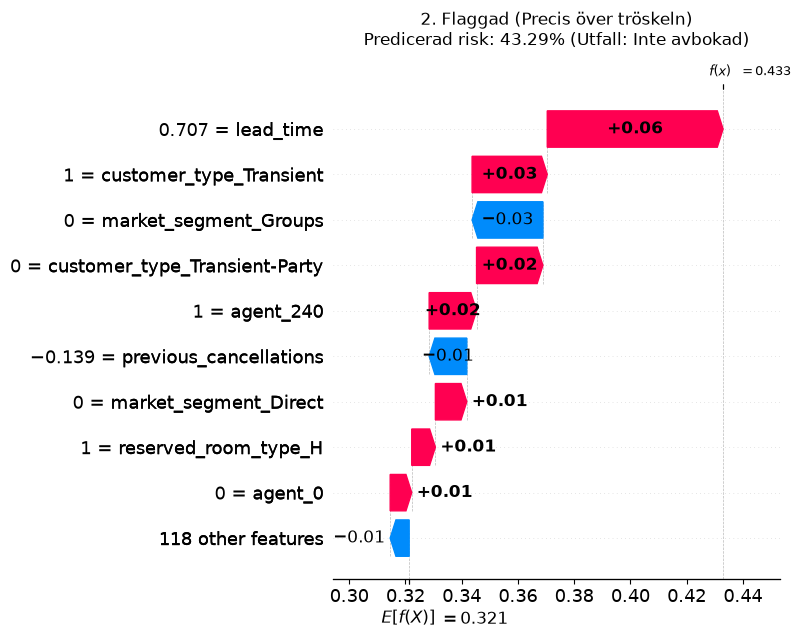

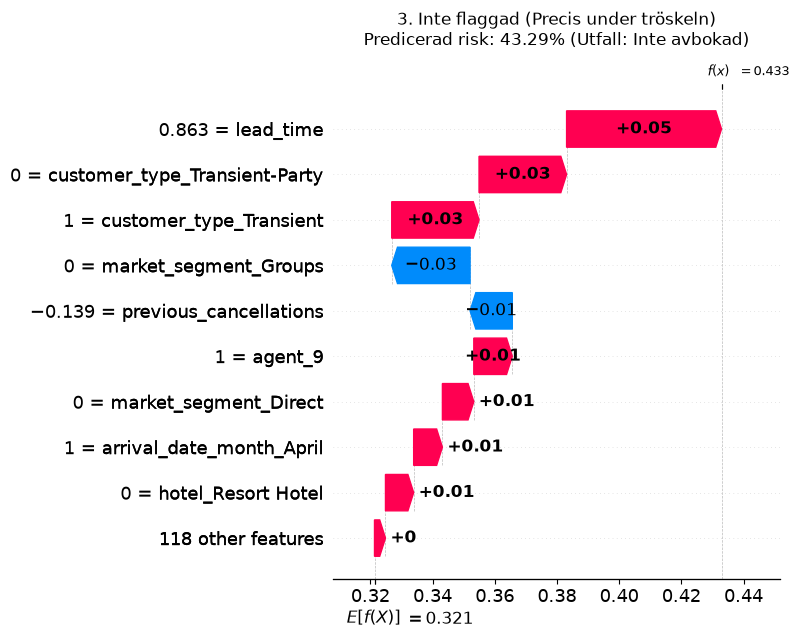

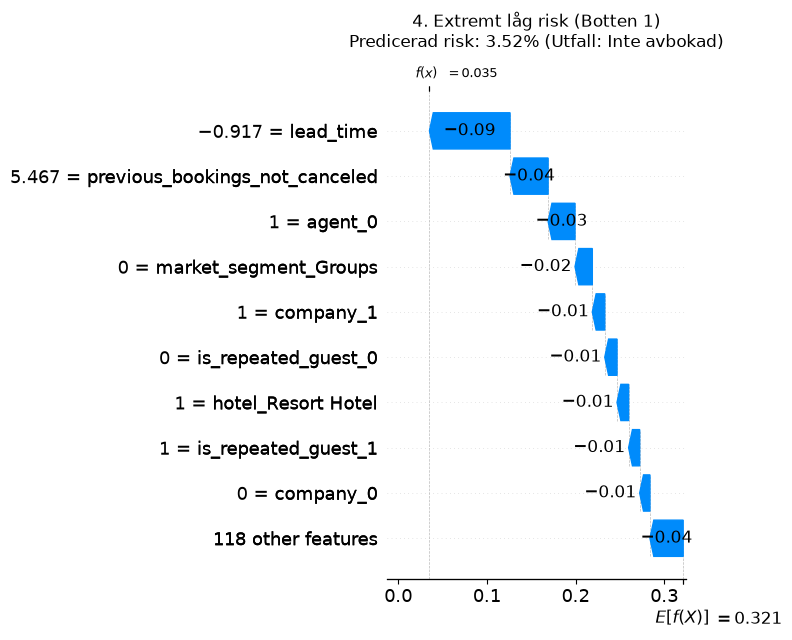

In [8]:
# 1. Hämta och snygga till kolumnnamnen
raw_feature_names = preprocessor.get_feature_names_out()

clean_feature_names = []
for name in raw_feature_names:
    clean_name = (
        name.replace("num__", "")
            .replace("cat__", "")
            .replace("agent__agent_", "agent_")
            .replace("agent__", "")
    )
    clean_feature_names.append(clean_name)

if hasattr(X_test_processed, "toarray"):
    X_test_df = pd.DataFrame(X_test_processed.toarray(), columns=clean_feature_names, index=test.index)
else:
    X_test_df = pd.DataFrame(X_test_processed, columns=clean_feature_names, index=test.index)

# 2. Beräkna SHAP-värden med TreeExplainer
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test_df)

if len(shap_values.shape) == 3:
    shap_values_class1 = shap_values[:, :, 1]
else:
    shap_values_class1 = shap_values

# Se till att de rensade namnen även följer med in i shap_values-objektet
shap_values_class1.feature_names = clean_feature_names

# 3. Rangordna testmängden efter predicerad sannolikhet
test_ranking = pd.DataFrame({
    "pred_prob": probas_rf,
    "is_canceled": y_test.values
}, index=np.arange(len(probas_rf))).sort_values(by="pred_prob", ascending=False)

# Tröskelvärde för topp 20 % flaggning
n_flagged = int(np.ceil(len(test_ranking) * 0.20)) # 2976
prob_cutoff = test_ranking.iloc[n_flagged - 1]["pred_prob"]

# 1. Extremt hög risk
idx_max = test_ranking.index[0]

# 2. Hitta sista bokningen som har STRIKT högre risk än tröskeln
strictly_above = test_ranking[test_ranking["pred_prob"] > prob_cutoff]
if len(strictly_above) > 0:
    idx_above = strictly_above.index[-1]
else:
    idx_above = test_ranking.index[n_flagged - 1]

# 3. Hitta första bokningen som har STRIKT lägre risk än tröskeln
strictly_below = test_ranking[test_ranking["pred_prob"] < prob_cutoff]
idx_below = strictly_below.index[0]

# 4. Extremt låg risk
idx_min = test_ranking.index[-1]

cases = [
    ("1. Extremt hög risk (Topp 1)", idx_max),
    ("2. Flaggad (Precis över tröskeln)", idx_above),
    ("3. Inte flaggad (Precis under tröskeln)", idx_below),
    ("4. Extremt låg risk (Botten 1)", idx_min)
]

for title, idx in cases:
    prob = test_ranking.loc[idx, 'pred_prob']
    actual = "Avbokad" if test_ranking.loc[idx, 'is_canceled'] == 1 else "Inte avbokad"
    print(f"{title}: Sannolikhet = {prob:.2%}, Faktiskt utfall = {actual}")

# 4. Rita Waterfall-plottar med ren och läsbar typografi
for title, idx in cases:
    prob = test_ranking.loc[idx, 'pred_prob']
    actual = "Avbokad" if test_ranking.loc[idx, 'is_canceled'] == 1 else "Inte avbokad"
    
    # Rita waterfall-plotten direkt
    shap.plots.waterfall(shap_values_class1[idx], max_display=10, show=False)
    
    fig = plt.gcf()
    ax = plt.gca()
    
    # 1. Gör all text svart och rensa bort fetstil från axlar
    for txt in fig.findobj(match=plt.matplotlib.text.Text):
        txt.set_color("#000000")
        # Behåll bara fetstil för pil-värdena (+0.06, -0.03 etc.)
        text_str = txt.get_text()
        if text_str.startswith("+") or text_str.startswith("-"):
            txt.set_fontweight("bold")
        else:
            txt.set_fontweight("normal")
            
    # 2. Snygga till x-axelns siffror specifikt (mindre och normal vikt)
    ax.tick_params(axis="x", labelsize=9)
    for label in ax.get_xticklabels():
        label.set_fontweight("normal")
        label.set_color("#000000")
            
    plt.title(f"{title}\nPredicerad risk: {prob:.2%} (Utfall: {actual})", fontsize=12, pad=15)
    plt.tight_layout()
    plt.show()

## 8. Slutsats och rekommendation

* **Modellbeslut:** Random Forest (`max_depth=15, min_samples_leaf=10`) utan `deposit_type` och `distribution_channel` gav högst precision och recall på vår testdata vid 20 % flaggning. Vi har försökt minska risken för dataläckage genom vårt val av variabler och vår tidsuppdelning, men kan inte helt utesluta att det förekommer.
* **Operativ nytta:** Modellen gör att hotellet med hög träffsäkerhet (drygt 8 av 10 rätt) kan sätta in riktade åtgärder - såsom bekräftelseförfrågningar, depositioner eller avbokningspåminnelser - mot de bokningar som mest sannolikt kommer att avbokas.
* **Individuellt beslutsstöd:** Tack vare SHAP kan hotellpersonalen snabbt se vilka faktorer (t.ex. lång ledtid, specifika agenter eller marknadssegment) som motiverar flaggningen.